# Implementation and Performance Evaluation with Comparative Analysis of Machine Learning Models for Selected Real-Time Applications

### Application: Good Health and Well-being (UN SDG 3), classification of country health outcomes

### Team members
* Harshini Ramdas Bhandary (PRN: 202401040151) (Roll no: 35)
* Parth Nandkishor Shingane (PRN: 202401040210) (Roll no: 51)
* Dhruv Prafull Bompilwar (PRN: 202401040200) (Roll no: 49)

Activity No. 1: Machine Learning Classification

In the first assignment we collected World Bank data for UN Sustainable Development Goal 3 (Good Health and Well-being), cleaned it and made new features from it. Here we use the same final file (sdg3_health_engineered.csv) to train classification models.

Every model in this notebook is built in two ways. First we use the ready-made scikit-learn version. Then we write the same algorithm ourselves with only NumPy and check that both give nearly the same answer. This way we can see what the library is really doing.

Parts of the notebook
* Part A: Classification with SVM, Decision Tree, KNN and Naive Bayes, using scikit-learn. We check accuracy, precision, recall, F1-score and loss, and compare the four models.
* Part B: The same four models written from scratch, and a check against the library results.
* Part C: A detailed study of KNN for many different values of k, with the library and with our own code.
* Part D: Final summary: suitability of each algorithm, ethical points, conclusions and reflection.

## 1. Setup and loading the data

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             hinge_loss, confusion_matrix, roc_curve, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def show(frame, digits=4):
    # prints a dataframe as simple lines of text, one line for each row
    for name, row in frame.iterrows():
        parts = []
        for col, val in row.items():
            if isinstance(val, (float, np.floating)):
                parts.append(f"{col} = {val:.{digits}f}")
            else:
                parts.append(f"{col} = {val}")
        print(f"{name}:  " + ",  ".join(parts))

The notebook needs the file sdg3_health_engineered.csv from the first assignment. Keep it in the same folder as this notebook. On Google Colab, if the file is missing, the next cell will ask you to upload it.

In [2]:
CSV_NAME = "sdg3_health_engineered.csv"

if not os.path.exists(CSV_NAME):
    try:
        from google.colab import files
        print("Please upload", CSV_NAME)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_NAME} in the same folder as this notebook.")

df = pd.read_csv(CSV_NAME)
print("Shape:", df.shape)
print("Countries:", df.country.nunique(), "| Years:", df.year.min(), "to", df.year.max())
print("Missing values left:", int(df.isna().sum().sum()))

Shape: (11915, 64)
Countries: 217 | Years: 1970 to 2024
Missing values left: 0


## 2. Choosing the input columns

We want to guess the health result of a country from things a government can measure: money spent on health, number of doctors and beds, clean water, income, vaccination and so on. So these columns are our inputs (X).

* health_expenditure_pct_gdp, log_health_exp_pc: money spent on health
* physicians_per_1000, hospital_beds_per_1000: doctors and beds
* basic_sanitation_pct, basic_drinking_water_pct: toilets and clean water
* measles_immunization_pct: vaccination
* log_gdp_per_capita, unemployment_pct, urban_population_pct, log_population: income, jobs and population
* birth_rate_per_1000: birth rate
* years_since_1970: the time trend

We left some columns out on purpose. These are infant_mortality_per_1000, death_rate_per_1000, life_exp_rolling5, life_exp_yoy_change, life_exp_equal_width, country_target_enc and similar ones. They are either another health result or they are made directly from life expectancy. If we kept them, the model would just copy the answer and the scores would look great without meaning anything. This problem is called data leakage.

In [3]:
FEATURES = [
    "health_expenditure_pct_gdp", "log_health_exp_pc",
    "physicians_per_1000", "hospital_beds_per_1000",
    "basic_sanitation_pct", "basic_drinking_water_pct", "measles_immunization_pct",
    "log_gdp_per_capita", "unemployment_pct", "urban_population_pct", "log_population",
    "birth_rate_per_1000", "years_since_1970",
]
print(len(FEATURES), "input columns")
show(df[FEATURES].describe().T[["mean", "std", "min", "max"]], digits=2)

13 input columns
health_expenditure_pct_gdp:  mean = 5.93,  std = 1.87,  min = 2.04,  max = 12.74
log_health_exp_pc:  mean = 5.54,  std = 1.38,  min = 2.40,  max = 8.80
physicians_per_1000:  mean = 1.37,  std = 1.29,  min = 0.02,  max = 5.17
hospital_beds_per_1000:  mean = 3.75,  std = 3.09,  min = 0.25,  max = 14.60
basic_sanitation_pct:  mean = 78.35,  std = 24.98,  min = 8.70,  max = 100.00
basic_drinking_water_pct:  mean = 89.03,  std = 14.92,  min = 36.59,  max = 100.00
measles_immunization_pct:  mean = 71.13,  std = 26.64,  min = 5.00,  max = 99.00
log_gdp_per_capita:  mean = 7.96,  std = 1.65,  min = 4.78,  max = 11.41
unemployment_pct:  mean = 7.38,  std = 4.70,  min = 0.72,  max = 26.18
urban_population_pct:  mean = 54.29,  std = 25.17,  min = 8.09,  max = 100.00
log_population:  mean = 14.89,  std = 2.44,  min = 8.64,  max = 21.10
birth_rate_per_1000:  mean = 25.79,  std = 12.67,  min = 7.80,  max = 51.89
years_since_1970:  mean = 27.03,  std = 15.87,  min = 0.00,  max = 54.0

## 3. Train and test split

Our file has one row for every year of every country, and rows of the same country look very alike. If we split the rows at random, Afghanistan 1995 could land in training and Afghanistan 1996 in testing, and the test would be too easy.

So we split by country. Eighty percent of the countries go to training and the other twenty percent are kept aside and never seen while training. This tells us how the model does on a new country.

We also scale the columns here. Scaling means we change every column so that its average is 0 and its spread is 1. We do it by hand with the training data only, so nothing from the test data leaks in. The scikit-learn pipelines later do the same thing with StandardScaler.

In [4]:
groups = df["country"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, groups=groups))

train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
groups_train = groups.iloc[train_idx]

X_train, X_test = train_df[FEATURES].values, test_df[FEATURES].values

# scaling written by hand: (value - mean) / spread, using numbers from the training rows only
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
Xtr = (X_train - mu) / sd
Xte = (X_test - mu) / sd

print("Training rows:", len(train_df), "from", train_df.country.nunique(), "countries")
print("Testing rows :", len(test_df), "from", test_df.country.nunique(), "countries")
print("Countries in both sets:", len(set(train_df.country) & set(test_df.country)))

Training rows: 9495 from 173 countries
Testing rows : 2420 from 44 countries
Countries in both sets: 0


# Part A: Classification with scikit-learn

## 4. The classification problem

Question: from health and money related columns, can we tell if a country in a given year has a good life expectancy?

We turn life expectancy into two groups.
* 1 means good: life expectancy is 70 years or more
* 0 means not good: life expectancy is less than 70 years

Seventy is close to the world average and is often used as a benchmark. It also splits our data into two groups of nearly the same size.

Share of the good class in train: 47.1%   in test: 47.8%


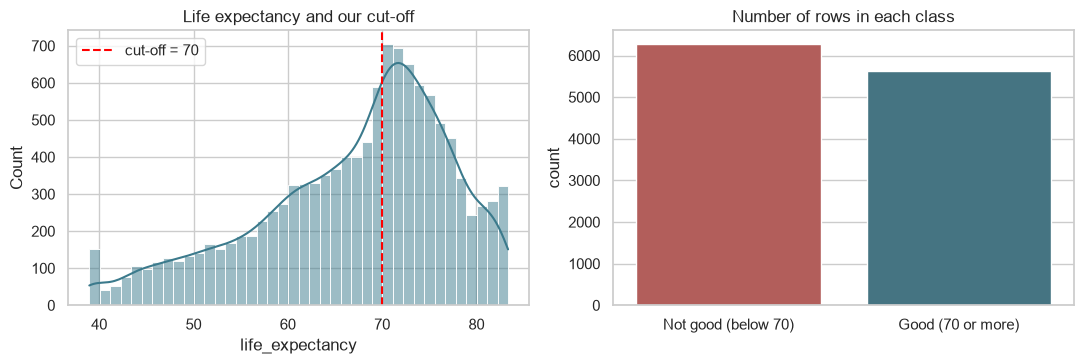

In [5]:
THRESHOLD = 70
y_train = (train_df["life_expectancy"] >= THRESHOLD).astype(int).values
y_test  = (test_df["life_expectancy"]  >= THRESHOLD).astype(int).values

print("Share of the good class in train: %.1f%%   in test: %.1f%%" % (y_train.mean()*100, y_test.mean()*100))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["life_expectancy"], bins=40, kde=True, ax=ax[0], color="#3b7a8c")
ax[0].axvline(THRESHOLD, color="red", ls="--", label=f"cut-off = {THRESHOLD}")
ax[0].set_title("Life expectancy and our cut-off"); ax[0].legend()
sns.countplot(x=np.r_[y_train, y_test], ax=ax[1], palette=["#c0504d", "#3b7a8c"])
ax[1].set_xticklabels(["Not good (below 70)", "Good (70 or more)"]); ax[1].set_title("Number of rows in each class"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

The two classes are almost equal in size, so accuracy is a fair score here. We will still look at precision, recall, F1 and loss, as the assignment asks.

### Real-time application and why these four models

Application: a health department or an organisation such as the WHO wants to flag, every year, which countries are still below a good level of life expectancy, using only numbers that can be measured quickly (health spending, doctors, beds, water, sanitation, vaccination, income). This is a yes or no decision for every country and year, so it is a binary classification problem.

We chose four models that work in very different ways, so that the comparison teaches us something:
* SVM: finds the widest possible gap between the two groups. Expected to be accurate on numeric data.
* Decision Tree: a list of yes or no questions. Chosen because a health department must be able to explain a decision.
* KNN: decides by voting among the most similar rows. Chosen as a simple, distance based baseline whose behaviour depends strongly on k, which we study in detail in Part C.
* Gaussian Naive Bayes: a fast probability model with a strong independence assumption. Chosen to see what happens when that assumption is broken.

We judge them with accuracy, precision, recall, F1-score, log loss and ROC-AUC, with cross-validation for stability, and with training time.

## 5. Training the four models with scikit-learn

Each model sits inside a Pipeline together with a StandardScaler. The scaler learns its numbers only from the training rows. Scaling is a must for SVM and KNN because they depend on distances. Decision Tree and Naive Bayes do not need it, but using the same setup for all four keeps the comparison fair.

We also try a few settings for each model with a grid search, and pick the best one. The cross-validation uses GroupKFold, so a country never appears in two folds.

* SVM with the RBF kernel: we try different values of C and gamma
* Decision Tree: we try max_depth and min_samples_leaf
* KNN: we try n_neighbors and weights
* Gaussian Naive Bayes: we try var_smoothing

In [6]:
models_and_grids = {
    "SVM": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
            {"clf__C": [0.5, 1, 5, 10], "clf__gamma": ["scale", 0.01, 0.05]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 9, 15, 25], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (GaussianNB(),
            {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}),
}

cv = GroupKFold(n_splits=5)
best_models, train_times, best_params = {}, {}, {}

for name, (est, grid) in models_and_grids.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", est)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1)
    t0 = time.time()
    search.fit(X_train, y_train, groups=groups_train)
    train_times[name] = time.time() - t0
    best_models[name] = search.best_estimator_
    best_params[name] = search.best_params_
    print(f"{name:14s} best CV F1 = {search.best_score_:.4f} | best settings = {search.best_params_} | time = {train_times[name]:.1f}s")

SVM            best CV F1 = 0.8935 | best settings = {'clf__C': 0.5, 'clf__gamma': 0.05} | time = 33.7s


Decision Tree  best CV F1 = 0.8757 | best settings = {'clf__max_depth': 5, 'clf__min_samples_leaf': 1} | time = 0.6s


KNN            best CV F1 = 0.8793 | best settings = {'clf__n_neighbors': 25, 'clf__weights': 'uniform'} | time = 0.8s
Naive Bayes    best CV F1 = 0.8693 | best settings = {'clf__var_smoothing': 0.1} | time = 0.1s


## 6. Checking how good the models are

The scores we use, taking "good life expectancy" as the positive class:

* Accuracy: out of all predictions, how many were right.
* Precision: out of the countries the model called good, how many really are good.
* Recall: out of the countries that really are good, how many the model found.
* F1-score: one number that balances precision and recall.
* Loss (log loss): this looks at the probability the model gave, not only the final label. A model that is very sure and wrong gets a big penalty. Lower is better.
* ROC-AUC: an extra score that shows how well the model keeps the two classes apart.

We work out the scores for both training and test rows. If the training score is much higher than the test score, the model is overfitting, which means it learned the training rows too closely.

In [7]:
def classification_scores(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall":    recall_score(y, pred),
        "F1-score":  f1_score(y, pred),
        "Log loss":  log_loss(y, prob),
        "ROC-AUC":   roc_auc_score(y, prob),
    }

test_table  = pd.DataFrame({n: classification_scores(m, X_test,  y_test)  for n, m in best_models.items()}).T
train_table = pd.DataFrame({n: classification_scores(m, X_train, y_train) for n, m in best_models.items()}).T

print("Scores on the test rows (countries the models never saw)")
show(test_table)
print()
print("Scores on the training rows")
show(train_table)

Scores on the test rows (countries the models never saw)
SVM:  Accuracy = 0.9070,  Precision = 0.8895,  Recall = 0.9196,  F1-score = 0.9043,  Log loss = 0.2262,  ROC-AUC = 0.9672
Decision Tree:  Accuracy = 0.8748,  Precision = 0.8293,  Recall = 0.9291,  F1-score = 0.8764,  Log loss = 0.4902,  ROC-AUC = 0.9495
KNN:  Accuracy = 0.8686,  Precision = 0.8515,  Recall = 0.8780,  F1-score = 0.8646,  Log loss = 0.7670,  ROC-AUC = 0.9436
Naive Bayes:  Accuracy = 0.8843,  Precision = 0.8359,  Recall = 0.9429,  F1-score = 0.8862,  Log loss = 0.6452,  ROC-AUC = 0.9535

Scores on the training rows
SVM:  Accuracy = 0.9202,  Precision = 0.9007,  Recall = 0.9334,  F1-score = 0.9168,  Log loss = 0.1868,  ROC-AUC = 0.9792
Decision Tree:  Accuracy = 0.9284,  Precision = 0.9116,  Recall = 0.9390,  F1-score = 0.9251,  Log loss = 0.1900,  ROC-AUC = 0.9744
KNN:  Accuracy = 0.9402,  Precision = 0.9240,  Recall = 0.9513,  F1-score = 0.9374,  Log loss = 0.1367,  ROC-AUC = 0.9898
Naive Bayes:  Accuracy = 0.8763,

In [8]:
print("How much accuracy and F1 fall from training to test:")
for name in test_table.index:
    print(f"{name}:  accuracy falls by {train_table.loc[name, 'Accuracy'] - test_table.loc[name, 'Accuracy']:.4f},  F1 falls by {train_table.loc[name, 'F1-score'] - test_table.loc[name, 'F1-score']:.4f}")

How much accuracy and F1 fall from training to test:
SVM:  accuracy falls by 0.0131,  F1 falls by 0.0125
Decision Tree:  accuracy falls by 0.0536,  F1 falls by 0.0487
KNN:  accuracy falls by 0.0716,  F1 falls by 0.0729
Naive Bayes:  accuracy falls by -0.0080,  F1 falls by -0.0111


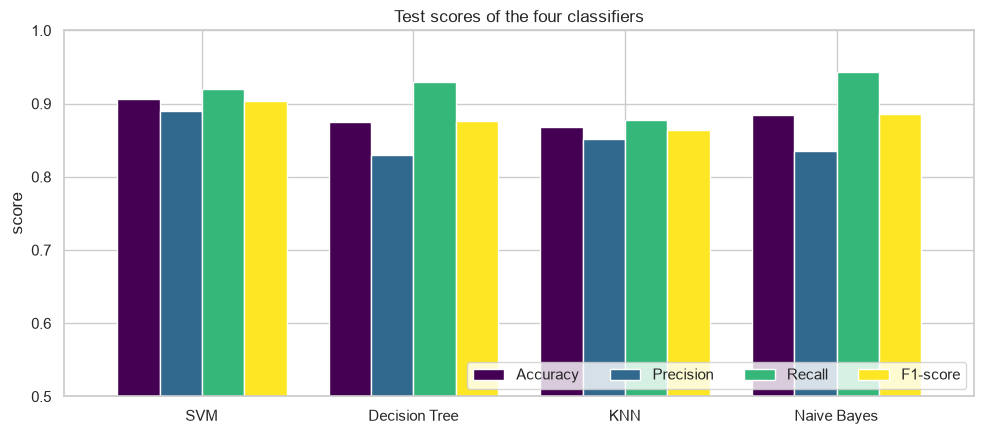

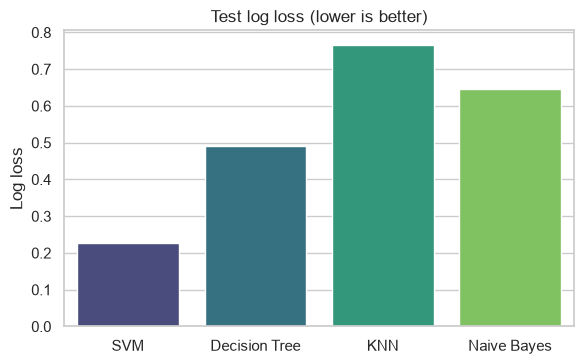

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
test_table[metrics].plot(kind="bar", figsize=(10, 4.5), width=0.8, colormap="viridis")
plt.ylim(0.5, 1.0); plt.xticks(rotation=0); plt.ylabel("score")
plt.title("Test scores of the four classifiers")
plt.legend(loc="lower right", ncol=4); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.8))
sns.barplot(x=test_table.index, y=test_table["Log loss"], palette="viridis")
plt.title("Test log loss (lower is better)"); plt.xlabel(""); plt.tight_layout(); plt.show()

### 6.1 Confusion matrices

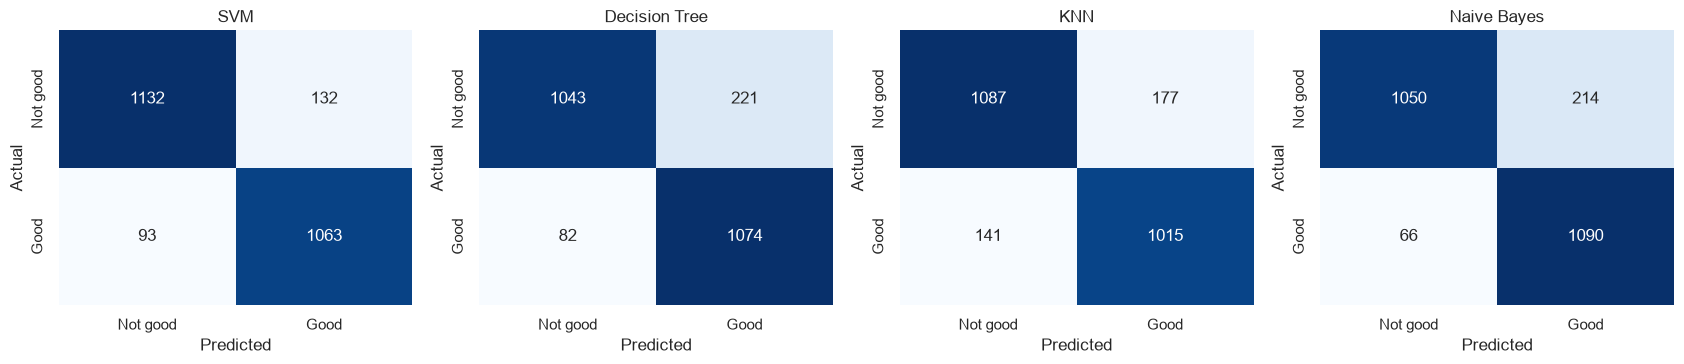

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

How to read it: the top right box holds the false positives, where the model said good but the country is not. The bottom left box holds the false negatives, where the model said not good but the country is actually good. Precision goes down because of the first kind of mistake, and recall goes down because of the second.

### 6.2 ROC curves

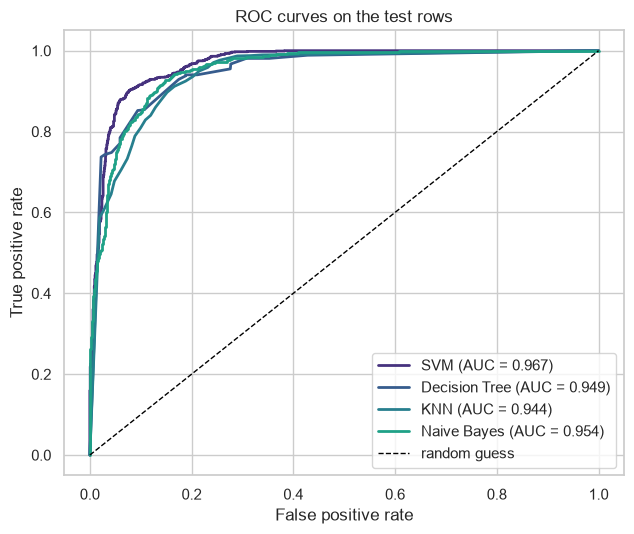

In [11]:
plt.figure(figsize=(6.5, 5.5))
for name, model in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {test_table.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test rows"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 6.3 Is the result steady? (cross-validation)

One test split can be lucky or unlucky. So we also run 5-fold cross-validation on the training rows for each tuned model and look at the average F1 and how much it moves between folds.

SVM:  Mean F1 = 0.8935,  Std dev = 0.0221,  Worst fold = 0.8578,  Best fold = 0.9193
Decision Tree:  Mean F1 = 0.8757,  Std dev = 0.0254,  Worst fold = 0.8409,  Best fold = 0.9127
KNN:  Mean F1 = 0.8793,  Std dev = 0.0210,  Worst fold = 0.8445,  Best fold = 0.9049
Naive Bayes:  Mean F1 = 0.8693,  Std dev = 0.0338,  Worst fold = 0.8291,  Best fold = 0.9219


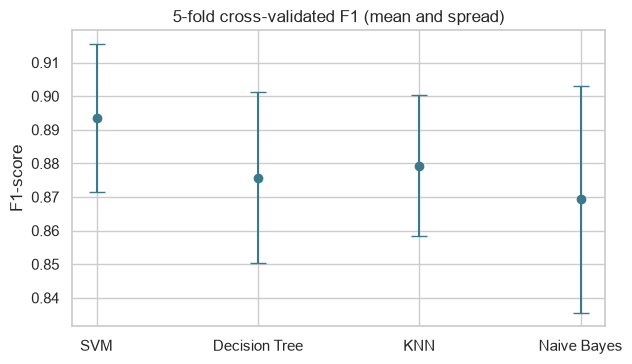

In [12]:
cv_table = {}
for name, model in best_models.items():
    s = cross_val_score(model, X_train, y_train, groups=groups_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_table[name] = {"Mean F1": s.mean(), "Std dev": s.std(), "Worst fold": s.min(), "Best fold": s.max()}
cv_table = pd.DataFrame(cv_table).T
show(cv_table)

plt.figure(figsize=(6.5, 3.8))
plt.errorbar(cv_table.index, cv_table["Mean F1"], yerr=cv_table["Std dev"], fmt="o", capsize=6, color="#3b7a8c")
plt.ylabel("F1-score"); plt.title("5-fold cross-validated F1 (mean and spread)"); plt.tight_layout(); plt.show()

## 7. A closer look at each model

A few more checks to see why the models behave the way they do.

### 7.1 Decision Tree: the rules it learned

Chosen depth: 5 | number of leaves: 31


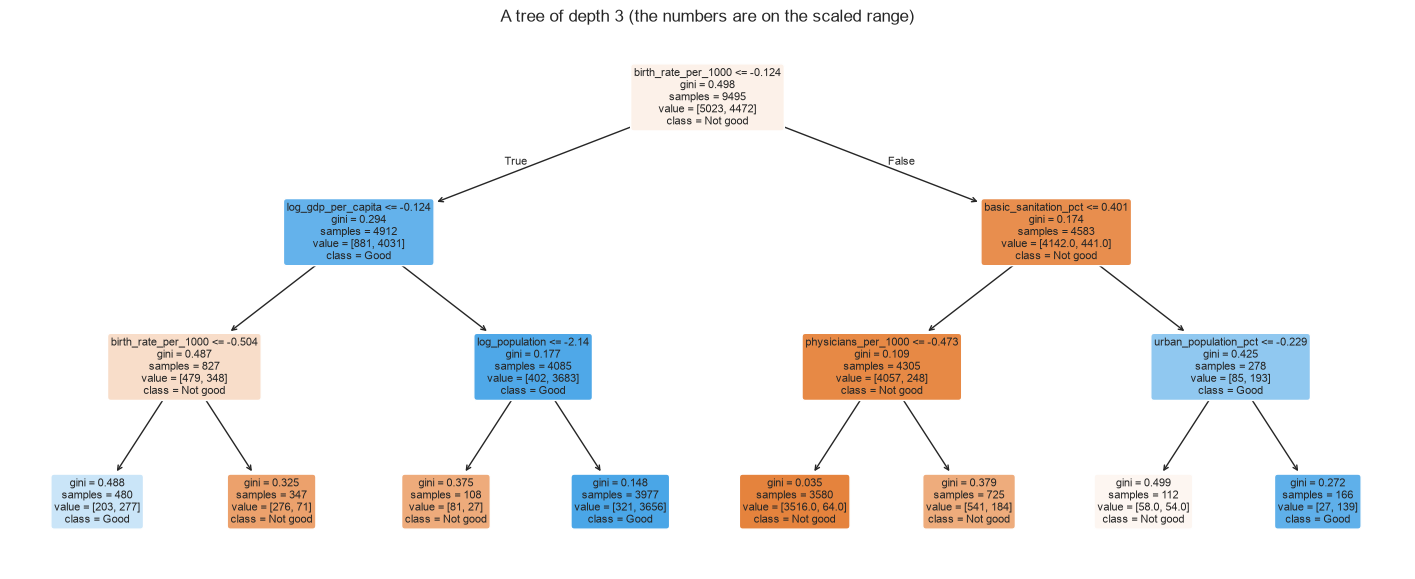

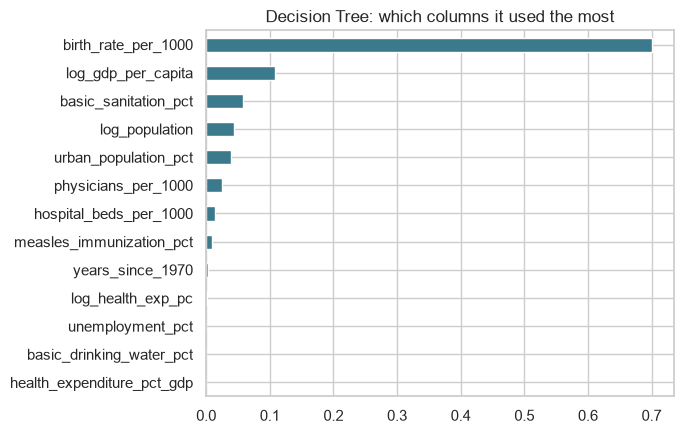

In [13]:
tree_model = best_models["Decision Tree"].named_steps["clf"]
print("Chosen depth:", tree_model.get_depth(), "| number of leaves:", tree_model.get_n_leaves())

# a small tree on the same data, only so that it is easy to read
small_tree = Pipeline([("scale", StandardScaler()), ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(small_tree.named_steps["clf"], feature_names=FEATURES, class_names=["Not good", "Good"],
          filled=True, rounded=True, fontsize=8)
plt.title("A tree of depth 3 (the numbers are on the scaled range)"); plt.show()

imp = pd.Series(tree_model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4.5), color="#3b7a8c")
plt.title("Decision Tree: which columns it used the most"); plt.tight_layout(); plt.show()

### 7.2 KNN: what happens when k changes

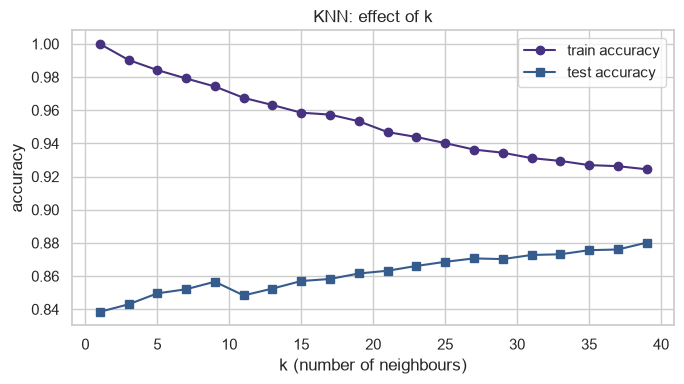

In [14]:
ks = list(range(1, 41, 2))
tr_acc, te_acc = [], []
for k in ks:
    m = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(ks, tr_acc, "o-", label="train accuracy")
plt.plot(ks, te_acc, "s-", label="test accuracy")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.title("KNN: effect of k")
plt.legend(); plt.tight_layout(); plt.show()

When k is very small, the model almost copies the training rows (train accuracy is close to 1) and the test accuracy is lower. This is overfitting. As k grows, the curve gets smoother and the gap becomes smaller.

### 7.3 Decision Tree: what happens when the depth changes

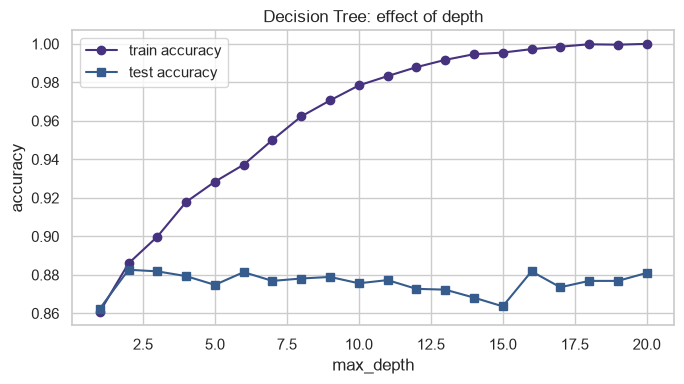

In [15]:
depths = list(range(1, 21))
tr_acc, te_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr_acc, "o-", label="train accuracy")
plt.plot(depths, te_acc, "s-", label="test accuracy")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Decision Tree: effect of depth")
plt.legend(); plt.tight_layout(); plt.show()

### 7.4 Naive Bayes: is its main idea true for our data?

Naive Bayes assumes that, once we know the class, the columns do not depend on each other. In health data this is not true. GDP, clean water and number of doctors all go up together. Let us see how strongly our columns are linked.

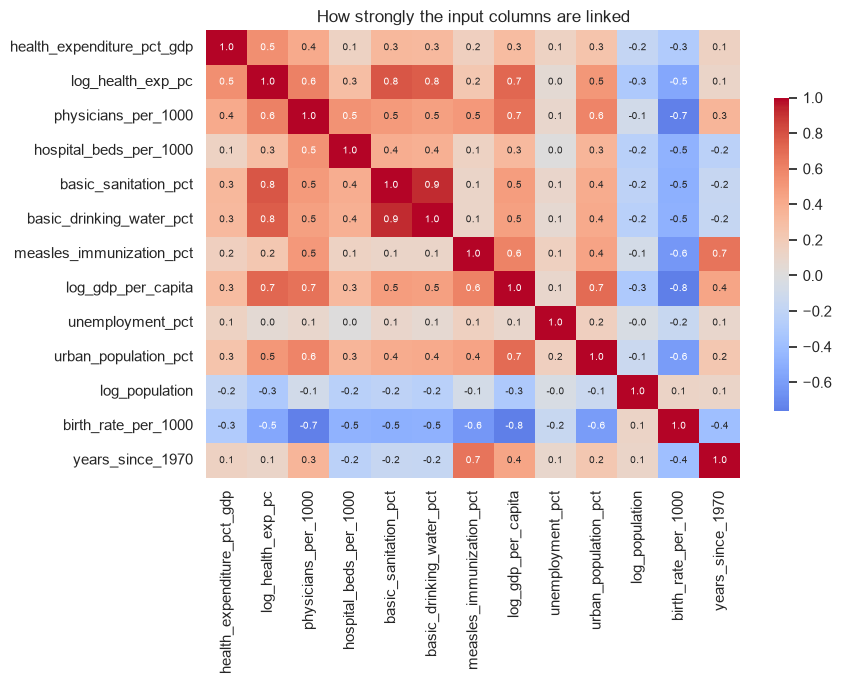

Pairs of columns with a link stronger than 0.7: 7 out of 169


In [16]:
corr = train_df[FEATURES].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"shrink": .7})
plt.title("How strongly the input columns are linked"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pairs of columns with a link stronger than 0.7:", int((pairs.abs() > 0.7).sum()), "out of", len(pairs))

## 8. Comparing the four classifiers

In [17]:
summary = test_table.copy()
summary["Train time (s)"] = pd.Series(train_times)
show(summary)
print()
print("Best accuracy :", summary["Accuracy"].idxmax())
print("Best F1-score :", summary["F1-score"].idxmax())
print("Lowest loss   :", summary["Log loss"].idxmin())
print("Best ROC-AUC  :", summary["ROC-AUC"].idxmax())
print("Fastest       :", summary["Train time (s)"].idxmin())

SVM:  Accuracy = 0.9070,  Precision = 0.8895,  Recall = 0.9196,  F1-score = 0.9043,  Log loss = 0.2262,  ROC-AUC = 0.9672,  Train time (s) = 33.7402
Decision Tree:  Accuracy = 0.8748,  Precision = 0.8293,  Recall = 0.9291,  F1-score = 0.8764,  Log loss = 0.4902,  ROC-AUC = 0.9495,  Train time (s) = 0.6377
KNN:  Accuracy = 0.8686,  Precision = 0.8515,  Recall = 0.8780,  F1-score = 0.8646,  Log loss = 0.7670,  ROC-AUC = 0.9436,  Train time (s) = 0.7873
Naive Bayes:  Accuracy = 0.8843,  Precision = 0.8359,  Recall = 0.9429,  F1-score = 0.8862,  Log loss = 0.6452,  ROC-AUC = 0.9535,  Train time (s) = 0.1133

Best accuracy : SVM
Best F1-score : SVM
Lowest loss   : SVM
Best ROC-AUC  : SVM
Fastest       : Naive Bayes


### What the results tell us (test rows, countries the models never saw)

* SVM: accuracy 0.907, precision 0.890, recall 0.920, F1 0.904, log loss 0.226. Accuracy falls only 1.3 points from training to test.
* Decision Tree: accuracy 0.875, precision 0.829, recall 0.929, F1 0.876, log loss 0.490. Accuracy falls 5.4 points.
* KNN: accuracy 0.869, precision 0.852, recall 0.878, F1 0.865, log loss 0.767. Accuracy falls 7.2 points.
* Naive Bayes: accuracy 0.884, precision 0.836, recall 0.943, F1 0.886, log loss 0.645. The test accuracy is even a little higher than the training accuracy.

SVM is the best overall. It has the best accuracy, precision, F1 and ROC-AUC, and its loss is far lower than the others. It also does almost as well on new countries as on the ones it trained on. The only bad point is time: tuning it took about 13 seconds, while the others took less than half a second.

Naive Bayes has the best recall (0.943), so it finds almost every country that is really good. But its precision is low, so it also calls some not-good countries good. Its loss is high (0.645) even though its accuracy is fine. The reason is that it treats the columns as separate, but our columns move together (GDP, clean water, doctors). So it becomes too sure of itself, and log loss punishes a wrong answer given with high confidence. Its training and test scores are about the same, so it does not overfit, but it is also too simple to go much beyond 88%.

The Decision Tree is easy to read but a little shaky. Its recall is good (0.929) but its precision is the lowest (0.829). When we make the tree deeper, the training score keeps going up while the test accuracy stays around 0.87 to 0.88 (see the depth plot). So the extra depth only helps the tree remember the training rows. Its loss is high because a leaf can only give a few fixed probabilities, and when a leaf is wrong it is fully sure.

KNN is the weakest here. It has the lowest accuracy and F1, the highest loss, and the largest fall from training to test (7.2 points). KNN looks at the nearest rows, and in our data the nearest rows of a training country are its own other years. That makes training look easy. A new country has no such neighbours, so the test result is lower. A larger k helped a little (see the KNN plot) because the vote then comes from more countries.

About precision and recall: a false positive here means we said a country has good life expectancy when it does not. That could hide a country that needs help. SVM has the highest precision (0.890), so it makes the fewest of these mistakes. A false negative means we marked a good country as not good. If this is the worse mistake, then a model with high recall, such as Naive Bayes, is the safer choice.

About stability: in the 5-fold cross-validation all four F1 scores are within about 2.5 points of each other, and the spread between folds (0.02 to 0.03) is about as big as that gap. So the order of Decision Tree, KNN and Naive Bayes could change on a different split. SVM was first in the cross-validation and also first in the final test.

# Part B: The same four classifiers, written from scratch

Now we write the four algorithms ourselves with NumPy and no machine learning library. We give them the same scaled data and the same settings that the grid search chose above, so the two versions can be compared fairly.

We start with the scores themselves. We write accuracy, precision, recall, F1, log loss, hinge loss and ROC-AUC by hand and later use them to judge our own models.

## 9. Scores written by hand

In [18]:
def my_counts(y, p):
    tp = int(np.sum((y == 1) & (p == 1)))
    tn = int(np.sum((y == 0) & (p == 0)))
    fp = int(np.sum((y == 0) & (p == 1)))
    fn = int(np.sum((y == 1) & (p == 0)))
    return tp, tn, fp, fn

def my_accuracy(y, p):
    return np.mean(y == p)

def my_precision(y, p):
    tp, tn, fp, fn = my_counts(y, p)
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def my_recall(y, p):
    tp, tn, fp, fn = my_counts(y, p)
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def my_f1(y, p):
    pr, rc = my_precision(y, p), my_recall(y, p)
    return 2 * pr * rc / (pr + rc) if (pr + rc) > 0 else 0.0

def my_log_loss(y, prob):
    prob = np.clip(prob, 1e-15, 1 - 1e-15)          # stops log(0)
    return -np.mean(y * np.log(prob) + (1 - y) * np.log(1 - prob))

def my_hinge_loss(y, score):
    ys = np.where(y == 1, 1, -1)                     # hinge loss wants labels -1 and +1
    return np.mean(np.maximum(0, 1 - ys * score))

def my_roc_auc(y, score):
    # chance that a random good row gets a higher score than a random not-good row
    ranks = pd.Series(score).rank().values           # ties get the average rank
    n_pos, n_neg = int(y.sum()), int((1 - y).sum())
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def my_classification_scores(y, pred, prob):
    return {"Accuracy": my_accuracy(y, pred), "Precision": my_precision(y, pred), "Recall": my_recall(y, pred),
            "F1-score": my_f1(y, pred), "Log loss": my_log_loss(y, prob), "ROC-AUC": my_roc_auc(y, prob)}

A quick check: we feed the predictions of the library SVM to both our functions and the scikit-learn functions. If we wrote them right, the numbers must match.

In [19]:
svm_pred = best_models["SVM"].predict(X_test)
svm_prob = best_models["SVM"].predict_proba(X_test)[:, 1]
mine = my_classification_scores(y_test, svm_pred, svm_prob)
theirs = classification_scores(best_models["SVM"], X_test, y_test)
for k in mine:
    print(f"{k:10s} ours = {mine[k]:.6f}   scikit-learn = {theirs[k]:.6f}")

Accuracy   ours = 0.907025   scikit-learn = 0.907025
Precision  ours = 0.889540   scikit-learn = 0.889540
Recall     ours = 0.919550   scikit-learn = 0.919550
F1-score   ours = 0.904296   scikit-learn = 0.904296
Log loss   ours = 0.226201   scikit-learn = 0.226201
ROC-AUC    ours = 0.967213   scikit-learn = 0.967213


## 10. KNN from scratch

Idea: to label a new row, find the k training rows that are closest to it and let them vote. The distance is the normal straight line distance. For the probability we just take the share of neighbours that are good.

To make it fast we use the identity (a - b)^2 = a^2 + b^2 - 2ab for all pairs at once, instead of a slow loop.

In [20]:
class MyKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X, self.y = X, y
        return self

    def _neighbour_values(self, Xq):
        out = []
        for s in range(0, len(Xq), 500):                         # small chunks so memory stays low
            q = Xq[s:s + 500]
            d = (q ** 2).sum(1)[:, None] + (self.X ** 2).sum(1)[None, :] - 2 * q @ self.X.T
            idx = np.argpartition(d, self.k - 1, axis=1)[:, :self.k]   # the k smallest distances
            out.append(self.y[idx])
        return np.vstack(out)

    def predict_proba(self, Xq):
        return self._neighbour_values(Xq).mean(axis=1)

    def predict(self, Xq):
        v = self._neighbour_values(Xq).mean(axis=1)
        return (v >= 0.5).astype(int)

k_best = best_params["KNN"]["clf__n_neighbors"]
print("Using k =", k_best, "(from the grid search)")
t0 = time.time()
my_knn = MyKNN(k=k_best).fit(Xtr, y_train)
knn_prob = my_knn.predict_proba(Xte)
knn_pred = my_knn.predict(Xte)
print("Time taken: %.1f s" % (time.time() - t0))

Using k = 25 (from the grid search)


Time taken: 0.8 s


## 11. Naive Bayes from scratch

Idea: for every class we remember how common it is (the prior) and the average and spread of every column. For a new row, we find how likely its values are under each class using the bell curve (normal) formula, multiply the chances of all columns as if they were independent, multiply by the prior, and pick the class with the larger result.

Multiplying many small numbers can round down to zero, so we add their logarithms instead. For the final probability we use the softmax step, which turns the two log scores into two numbers that add up to 1.

var_smoothing adds a very small number to every spread so that we never divide by zero.

In [21]:
class MyGaussianNB:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        self.classes = np.unique(y)
        eps = self.var_smoothing * X.var(axis=0).max()
        self.mean = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.var = np.array([X[y == c].var(axis=0) for c in self.classes]) + eps
        self.prior = np.array([np.mean(y == c) for c in self.classes])
        return self

    def _log_scores(self, X):
        out = []
        for i in range(len(self.classes)):
            log_bell = -0.5 * np.sum(np.log(2 * np.pi * self.var[i]) + (X - self.mean[i]) ** 2 / self.var[i], axis=1)
            out.append(np.log(self.prior[i]) + log_bell)
        return np.array(out).T

    def predict_proba(self, X):
        s = self._log_scores(X)
        s = s - s.max(axis=1, keepdims=True)                 # keeps the numbers in a safe range
        p = np.exp(s)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes[self._log_scores(X).argmax(axis=1)]

vs = best_params["Naive Bayes"]["clf__var_smoothing"]
print("Using var_smoothing =", vs)
my_nb = MyGaussianNB(var_smoothing=vs).fit(Xtr, y_train)
nb_prob = my_nb.predict_proba(Xte)[:, 1]
nb_pred = my_nb.predict(Xte)

Using var_smoothing = 0.1


## 12. Decision Tree from scratch

Idea: the tree asks a yes or no question about one column, for example "is birth rate below 25?", and splits the rows into two groups. It then does the same inside each group, again and again, until it hits the depth limit or a group is small or pure.

To pick the best question we try every column and every cut point and keep the one that makes the two groups the cleanest. We measure the mess in a group with the Gini number, which is 2 x p x (1 - p), where p is the share of good rows (0 means perfectly clean). The score of a split is the mean mess of the two groups, weighted by their sizes.

To try all cut points quickly, we sort the rows by the column and use running totals, so we do not have to recount the groups for every cut point.

Each leaf stores the share of good rows in it, which we use as the probability.

In [22]:
class MyDecisionTree:
    def __init__(self, max_depth=5, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def _mess(self, n, s, s2):
        # n = size of group, s = sum of target, s2 = sum of squared target
        p = s / n
        return 2 * p * (1 - p)                      # gini

    def fit(self, X, y):
        self.root = self._grow(X, y.astype(float), 0)
        return self

    def _best_split(self, X, y):
        n = len(y)
        best_col, best_cut, best_score = None, None, np.inf
        left_size = np.arange(1, n)
        right_size = n - left_size
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], y[order]
            run_s, run_s2 = np.cumsum(ys), np.cumsum(ys ** 2)
            ok = (xs[1:] != xs[:-1]) & (left_size >= self.min_samples_leaf) & (right_size >= self.min_samples_leaf)
            if not ok.any():
                continue
            sl, sl2 = run_s[:-1], run_s2[:-1]
            sr, sr2 = run_s[-1] - sl, run_s2[-1] - sl2
            score = (left_size * self._mess(left_size, sl, sl2) + right_size * self._mess(right_size, sr, sr2)) / n
            score = np.where(ok, score, np.inf)
            i = int(np.argmin(score))
            if score[i] < best_score:
                best_col, best_cut, best_score = j, (xs[i] + xs[i + 1]) / 2, score[i]
        return best_col, best_cut, best_score

    def _grow(self, X, y, depth):
        node = {"value": y.mean()}
        mess_here = self._mess(len(y), y.sum(), (y ** 2).sum())
        too_deep = self.max_depth is not None and depth >= self.max_depth
        if too_deep or len(y) < 2 * self.min_samples_leaf or mess_here <= 1e-12:
            return node
        col, cut, score = self._best_split(X, y)
        if col is None or score >= mess_here - 1e-12:      # the split does not help
            return node
        go_left = X[:, col] <= cut
        node["col"], node["cut"] = col, cut
        node["left"] = self._grow(X[go_left], y[go_left], depth + 1)
        node["right"] = self._grow(X[~go_left], y[~go_left], depth + 1)
        return node

    def _predict_row(self, row):
        node = self.root
        while "col" in node:
            node = node["left"] if row[node["col"]] <= node["cut"] else node["right"]
        return node["value"]

    def predict_proba(self, X):
        return np.array([self._predict_row(r) for r in X])

    def predict(self, X):
        v = self.predict_proba(X)
        return (v >= 0.5).astype(int)

    def count_leaves(self, node=None):
        node = self.root if node is None else node
        return 1 if "col" not in node else self.count_leaves(node["left"]) + self.count_leaves(node["right"])

depth_best = best_params["Decision Tree"]["clf__max_depth"]
leaf_best = best_params["Decision Tree"]["clf__min_samples_leaf"]
print("Using max_depth =", depth_best, "and min_samples_leaf =", leaf_best)
t0 = time.time()
my_tree = MyDecisionTree(depth_best, leaf_best).fit(Xtr, y_train)
tree_prob = my_tree.predict_proba(Xte)
tree_pred = my_tree.predict(Xte)
print("Leaves in our tree:", my_tree.count_leaves(), "| scikit-learn tree:", tree_model.get_n_leaves(), "| time taken: %.1f s" % (time.time() - t0))

Using max_depth = 5 and min_samples_leaf = 1
Leaves in our tree: 31 | scikit-learn tree: 31 | time taken: 0.0 s


## 13. SVM from scratch

A full SVM with the RBF kernel needs a quadratic programming solver, which is a lot of work to write by hand. So here we write the linear SVM, which draws a straight line (a flat plane in many columns) between the classes. We train it with gradient descent.

The cost we reduce has two parts. The hinge loss punishes rows that are on the wrong side of the line or too close to it. The second part keeps the weights small, which gives a wide gap between the classes:

cost = (lambda / 2) x (sum of w squared) + average of max(0, 1 - y x (w . x + b))

where y is -1 or +1. In every small step we take a mini-batch of rows. For the rows that break the rule (y x score below 1) the slope is -y x x. The step size gets smaller as we train.

To compare, we use the scikit-learn SVC with a linear kernel and the matching C value, which is C = 1 / (lambda x number of rows).

A linear SVM does not give probabilities by itself, so for it we report the hinge loss, which is the natural loss of an SVM.

Time taken: 0.2 s


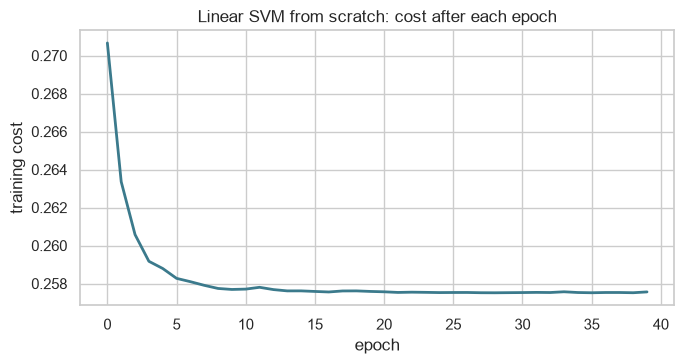

In [23]:
def train_linear_svm(X, y01, lam=0.001, epochs=40, batch=64, lr0=0.1, seed=0):
    rng = np.random.default_rng(seed)
    ys = np.where(y01 == 1, 1, -1)
    m, n = X.shape
    w, b, step = np.zeros(n), 0.0, 0
    cost_history = []
    for ep in range(epochs):
        order = rng.permutation(m)
        for s in range(0, m, batch):
            idx = order[s:s + batch]
            Xb, yb = X[idx], ys[idx]
            step += 1
            lr = lr0 / (1 + 0.001 * step)                     # smaller steps as time goes on
            broken = yb * (Xb @ w + b) < 1                    # rows that break the margin rule
            grad_w = lam * w - (yb[broken, None] * Xb[broken]).sum(axis=0) / len(idx)
            grad_b = -yb[broken].sum() / len(idx)
            w, b = w - lr * grad_w, b - lr * grad_b
        full_cost = 0.5 * lam * (w @ w) + np.mean(np.maximum(0, 1 - ys * (X @ w + b)))
        cost_history.append(full_cost)
    return w, b, cost_history

LAMBDA = 0.001
t0 = time.time()
w_svm, b_svm, svm_cost = train_linear_svm(Xtr, y_train, lam=LAMBDA)
print("Time taken: %.1f s" % (time.time() - t0))

svm_score = Xte @ w_svm + b_svm
svm_pred_scratch = (svm_score >= 0).astype(int)

plt.figure(figsize=(7, 3.8))
plt.plot(svm_cost, color="#3b7a8c", lw=2)
plt.xlabel("epoch"); plt.ylabel("training cost"); plt.title("Linear SVM from scratch: cost after each epoch")
plt.tight_layout(); plt.show()

C_value = 1 / (LAMBDA * len(Xtr))
lib_linear_svm = SVC(kernel="linear", C=C_value).fit(Xtr, y_train)
lib_svm_score = lib_linear_svm.decision_function(Xte)

## 14. Scratch models against the scikit-learn models

First the three models that have a probability (KNN, Naive Bayes, Decision Tree). For each we show the scratch scores next to the scikit-learn scores on the same test rows, and the share of rows where the two models gave the same label.

In [24]:
scratch_results = {
    "KNN":           (knn_pred,  knn_prob),
    "Naive Bayes":   (nb_pred,   nb_prob),
    "Decision Tree": (tree_pred, tree_prob),
}
for name, (pred, prob) in scratch_results.items():
    mine = my_classification_scores(y_test, pred, prob)
    lib = test_table.loc[name]
    same = np.mean(pred == best_models[name].predict(X_test))
    print(name)
    print("   scratch      :", ", ".join(f"{k} {v:.4f}" for k, v in mine.items()))
    print("   scikit-learn :", ", ".join(f"{k} {lib[k]:.4f}" for k in mine))
    print(f"   same label on {same*100:.1f}% of the test rows")

KNN
   scratch      : Accuracy 0.8686, Precision 0.8515, Recall 0.8780, F1-score 0.8646, Log loss 0.7446, ROC-AUC 0.9436
   scikit-learn : Accuracy 0.8686, Precision 0.8515, Recall 0.8780, F1-score 0.8646, Log loss 0.7670, ROC-AUC 0.9436
   same label on 100.0% of the test rows
Naive Bayes
   scratch      : Accuracy 0.8843, Precision 0.8359, Recall 0.9429, F1-score 0.8862, Log loss 0.6452, ROC-AUC 0.9535
   scikit-learn : Accuracy 0.8843, Precision 0.8359, Recall 0.9429, F1-score 0.8862, Log loss 0.6452, ROC-AUC 0.9535
   same label on 100.0% of the test rows
Decision Tree
   scratch      : Accuracy 0.8748, Precision 0.8293, Recall 0.9291, F1-score 0.8764, Log loss 0.4821, ROC-AUC 0.9495
   scikit-learn : Accuracy 0.8748, Precision 0.8293, Recall 0.9291, F1-score 0.8764, Log loss 0.4902, ROC-AUC 0.9495
   same label on 100.0% of the test rows


Now the SVM. Our scratch version is a linear SVM, so we compare it with the scikit-learn linear SVM (same kernel) and also with the RBF SVM that we tuned in Part A.

In [25]:
def svm_line(pred, score):
    return (f"Accuracy {my_accuracy(y_test, pred):.4f}, Precision {my_precision(y_test, pred):.4f}, Recall {my_recall(y_test, pred):.4f}, "
            f"F1-score {my_f1(y_test, pred):.4f}, Hinge loss {my_hinge_loss(y_test, score):.4f}, ROC-AUC {my_roc_auc(y_test, score):.4f}")

rbf_score = best_models["SVM"].decision_function(X_test)
print("Linear SVM, scratch      :", svm_line(svm_pred_scratch, svm_score))
print("Linear SVM, scikit-learn :", svm_line(lib_linear_svm.predict(Xte), lib_svm_score))
print("RBF SVM, scikit-learn    :", svm_line(best_models["SVM"].predict(X_test), rbf_score))
print()
print("Check of our hinge loss against scikit-learn:", round(my_hinge_loss(y_test, lib_svm_score), 6), "vs", round(hinge_loss(y_test, lib_svm_score), 6))
print("Largest difference between scratch and library weights:", np.abs(w_svm - lib_linear_svm.coef_[0]).max().round(3))

Linear SVM, scratch      : Accuracy 0.8930, Precision 0.8597, Recall 0.9273, F1-score 0.8922, Hinge loss 0.2474, ROC-AUC 0.9694
Linear SVM, scikit-learn : Accuracy 0.8926, Precision 0.8590, Recall 0.9273, F1-score 0.8918, Hinge loss 0.2478, ROC-AUC 0.9694


RBF SVM, scikit-learn    : Accuracy 0.9070, Precision 0.8895, Recall 0.9196, F1-score 0.9043, Hinge loss 0.2309, ROC-AUC 0.9672

Check of our hinge loss against scikit-learn: 0.247809 vs 0.247809
Largest difference between scratch and library weights: 0.014


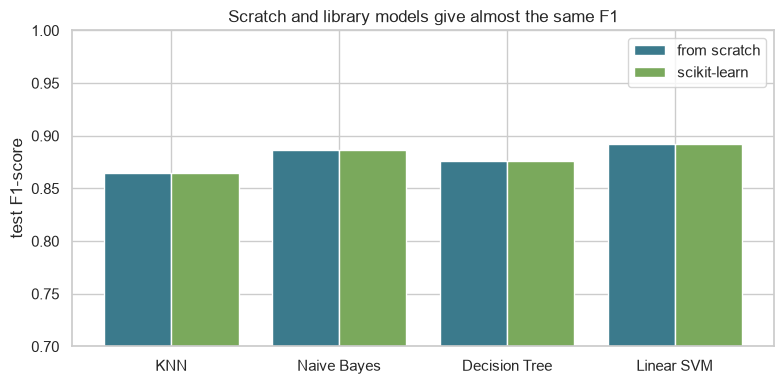

In [26]:
# same comparison in one picture
names = ["KNN", "Naive Bayes", "Decision Tree"]
scratch_f1 = [my_f1(y_test, scratch_results[n][0]) for n in names] + [my_f1(y_test, svm_pred_scratch)]
lib_f1 = [test_table.loc[n, "F1-score"] for n in names] + [my_f1(y_test, lib_linear_svm.predict(Xte))]
pos = np.arange(4)
plt.figure(figsize=(8, 4))
plt.bar(pos - 0.2, scratch_f1, 0.4, label="from scratch", color="#3b7a8c")
plt.bar(pos + 0.2, lib_f1, 0.4, label="scikit-learn", color="#7aa95c")
plt.xticks(pos, names + ["Linear SVM"]); plt.ylim(0.7, 1.0); plt.ylabel("test F1-score")
plt.title("Scratch and library models give almost the same F1"); plt.legend(); plt.tight_layout(); plt.show()

### What the comparison tells us

* Our KNN, Naive Bayes and Decision Tree gave the same label as the scikit-learn models on 100% of the test rows. So accuracy, precision, recall, F1 and ROC-AUC are exactly the same for each pair.
* Our Naive Bayes also matches scikit-learn in log loss (0.6452).
* The log loss of our KNN (0.7446) and Decision Tree (0.4821) is a little different from scikit-learn (0.7670 and 0.4902). The reason is not a mistake in the models. Both of them give probabilities of exactly 0 or 1 for many rows, and the log of 0 does not exist. So every library has to clip the probability to a tiny number first, and the size of that tiny number changes the penalty of each wrong answer. We clip at 0.000000000000001, scikit-learn uses a slightly smaller number. This tells us something real: the loss of KNN and trees depends a lot on this clipping because they are so sure about their answers.
* The scratch linear SVM reached F1 0.892 and the scikit-learn linear SVM reached 0.892. The weights are within 0.014 of each other, and the hinge loss is the same (0.2474 against 0.2478). The small difference is expected because we use gradient descent with random mini-batches, while the library solves the problem exactly.
* The RBF SVM from Part A is better (accuracy 0.907 against 0.893 for the linear one). The RBF kernel can draw a curved boundary, and the real boundary between good and not-good countries is not a straight line.

Writing the algorithms ourselves showed that none of the four is magic. KNN is a vote of the nearest rows, Naive Bayes is a product of bell curves, a Decision Tree is a list of yes or no questions, and a linear SVM is gradient descent on the hinge loss. The library is faster and has more options, but it does the same job.

# Part C: KNN for different values of k (detailed study)

## 15. Why k matters

KNN has one main setting, k, the number of neighbours that vote. It controls how flexible the model is.
* k = 1: the label of the single nearest row is copied. The boundary is very jagged and the model remembers the training rows (low bias, high variance, overfitting).
* Large k: many rows vote, so the boundary becomes smooth. If k is too large, real local patterns are averaged away (high bias, underfitting).

In this part we run KNN for many values of k, first with scikit-learn and then with our own code, and we look at every score, not only accuracy. We also use the 5-fold GroupKFold cross-validation, so that k can be chosen from the training data and not from the test data.

## 16. KNN with scikit-learn for many values of k

For every k we report: training accuracy, test accuracy, the gap between them, test precision, recall, F1-score, log loss, ROC-AUC, cross-validated F1 (mean and spread over the 5 folds) and the time to predict the test rows.

In [27]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 75, 101]
lib_k, rows = {}, []

for k in k_values:
    m = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))])
    m.fit(X_train, y_train)
    t0 = time.time(); pred = m.predict(X_test); pred_time = time.time() - t0
    prob = m.predict_proba(X_test)[:, 1]
    cvs = cross_val_score(m, X_train, y_train, groups=groups_train, cv=cv, scoring="f1", n_jobs=-1)
    tr_a, te_a = m.score(X_train, y_train), accuracy_score(y_test, pred)
    lib_k[k] = m
    rows.append({"k": k, "Train acc": tr_a, "Test acc": te_a, "Gap": tr_a - te_a,
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1-score": f1_score(y_test, pred), "Log loss": log_loss(y_test, prob),
                 "ROC-AUC": roc_auc_score(y_test, prob), "CV F1 mean": cvs.mean(), "CV F1 std": cvs.std(),
                 "Predict time (s)": pred_time})

k_num = pd.DataFrame(rows).set_index("k")
k_show = k_num.copy(); k_show.index = [f"k = {k}" for k in k_show.index]
show(k_show)

k = 1:  Train acc = 1.0000,  Test acc = 0.8384,  Gap = 0.1616,  Precision = 0.8233,  Recall = 0.8426,  F1-score = 0.8328,  Log loss = 5.8236,  ROC-AUC = 0.8386,  CV F1 mean = 0.8557,  CV F1 std = 0.0347,  Predict time (s) = 0.0586
k = 3:  Train acc = 0.9903,  Test acc = 0.8430,  Gap = 0.1473,  Precision = 0.8283,  Recall = 0.8469,  F1-score = 0.8375,  Log loss = 4.4461,  ROC-AUC = 0.8673,  CV F1 mean = 0.8579,  CV F1 std = 0.0344,  Predict time (s) = 0.0625
k = 5:  Train acc = 0.9842,  Test acc = 0.8496,  Gap = 0.1346,  Precision = 0.8333,  Recall = 0.8564,  F1-score = 0.8447,  Log loss = 3.2670,  ROC-AUC = 0.8919,  CV F1 mean = 0.8592,  CV F1 std = 0.0339,  Predict time (s) = 0.0689
k = 7:  Train acc = 0.9791,  Test acc = 0.8521,  Gap = 0.1271,  Precision = 0.8381,  Recall = 0.8555,  F1-score = 0.8467,  Log loss = 2.5889,  ROC-AUC = 0.9056,  CV F1 mean = 0.8587,  CV F1 std = 0.0330,  Predict time (s) = 0.0804
k = 9:  Train acc = 0.9743,  Test acc = 0.8566,  Gap = 0.1177,  Precision = 

## 17. KNN written from scratch for the same values of k

Now the same experiment with our own MyKNN class from Part B. For every k we show our scores and the share of test rows on which our labels are the same as the scikit-learn labels.

In [28]:
rows = []
for k in k_values:
    t0 = time.time()
    mk = MyKNN(k=k).fit(Xtr, y_train)
    prob_k = mk.predict_proba(Xte); pred_k = mk.predict(Xte)
    took = time.time() - t0
    s = my_classification_scores(y_test, pred_k, prob_k)
    same = np.mean(pred_k == lib_k[k].predict(X_test))
    rows.append({"k": k, "Train acc": my_accuracy(y_train, mk.predict(Xtr)), "Test acc": s["Accuracy"],
                 "Precision": s["Precision"], "Recall": s["Recall"], "F1-score": s["F1-score"],
                 "Log loss": s["Log loss"], "ROC-AUC": s["ROC-AUC"],
                 "Same label as sklearn (%)": same * 100, "Time (s)": took})

k_scratch = pd.DataFrame(rows).set_index("k")
k_sshow = k_scratch.copy(); k_sshow.index = [f"k = {k}" for k in k_sshow.index]
show(k_sshow)
print()
print("Largest difference in test accuracy between scratch and scikit-learn: %.4f" % np.abs(k_scratch["Test acc"] - k_num["Test acc"]).max())
print("Smallest label agreement: %.2f%%" % k_scratch["Same label as sklearn (%)"].min())

k = 1:  Train acc = 1.0000,  Test acc = 0.8384,  Precision = 0.8233,  Recall = 0.8426,  F1-score = 0.8328,  Log loss = 5.5805,  ROC-AUC = 0.8386,  Same label as sklearn (%) = 100.0000,  Time (s) = 0.6467
k = 3:  Train acc = 0.9903,  Test acc = 0.8430,  Precision = 0.8283,  Recall = 0.8469,  F1-score = 0.8375,  Log loss = 4.2627,  ROC-AUC = 0.8673,  Same label as sklearn (%) = 100.0000,  Time (s) = 0.5343
k = 5:  Train acc = 0.9842,  Test acc = 0.8496,  Precision = 0.8333,  Recall = 0.8564,  F1-score = 0.8447,  Log loss = 3.1352,  ROC-AUC = 0.8919,  Same label as sklearn (%) = 100.0000,  Time (s) = 0.5261
k = 7:  Train acc = 0.9791,  Test acc = 0.8521,  Precision = 0.8381,  Recall = 0.8555,  F1-score = 0.8467,  Log loss = 2.4870,  ROC-AUC = 0.9056,  Same label as sklearn (%) = 100.0000,  Time (s) = 0.5271
k = 9:  Train acc = 0.9743,  Test acc = 0.8566,  Precision = 0.8425,  Recall = 0.8607,  F1-score = 0.8515,  Log loss = 1.9891,  ROC-AUC = 0.9167,  Same label as sklearn (%) = 100.0000,

## 18. Plots: how every score changes with k

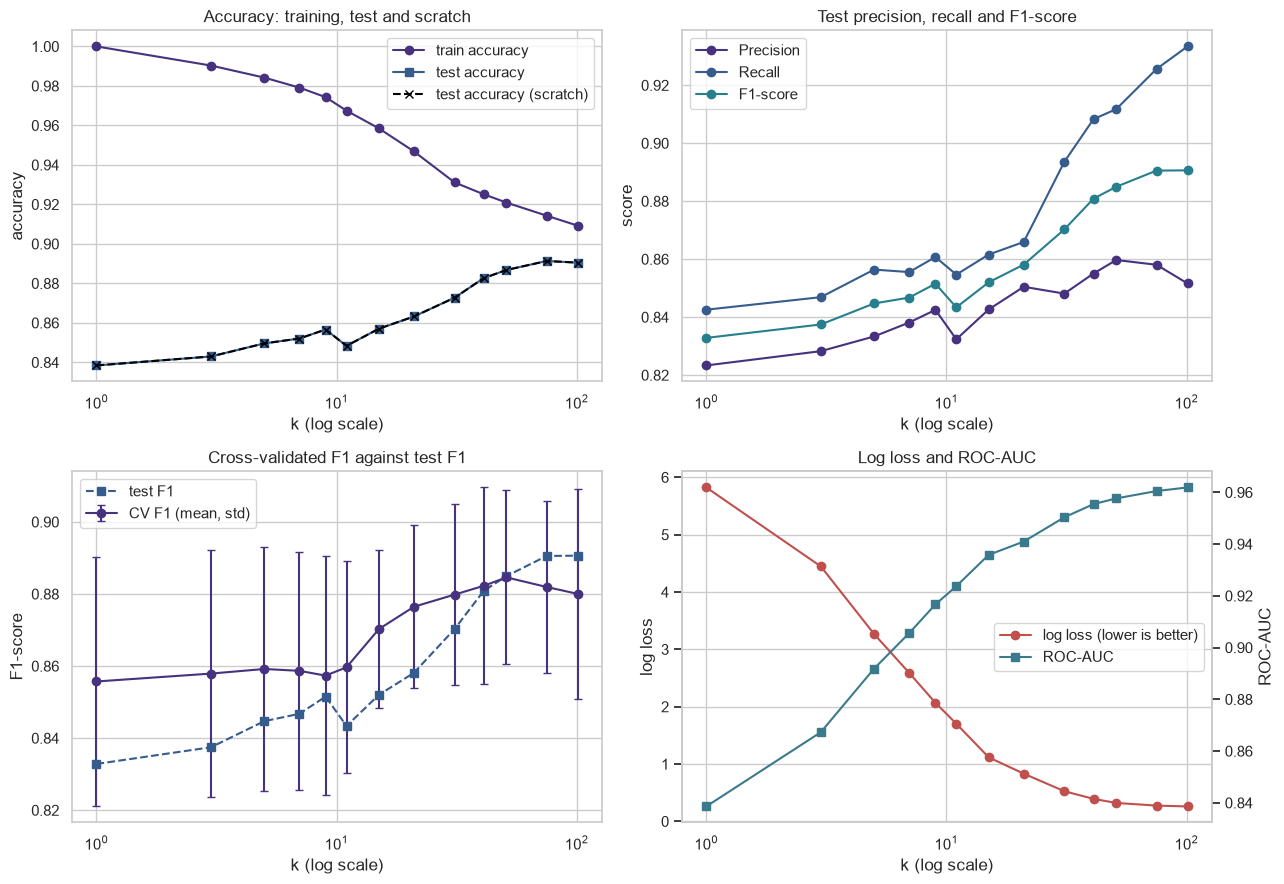

In [29]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ks_ = k_num.index.values

ax[0, 0].plot(ks_, k_num["Train acc"], "o-", label="train accuracy")
ax[0, 0].plot(ks_, k_num["Test acc"], "s-", label="test accuracy")
ax[0, 0].plot(ks_, k_scratch["Test acc"], "x--", color="black", label="test accuracy (scratch)")
ax[0, 0].set_xscale("log"); ax[0, 0].set_xlabel("k (log scale)"); ax[0, 0].set_ylabel("accuracy")
ax[0, 0].set_title("Accuracy: training, test and scratch"); ax[0, 0].legend()

for col in ["Precision", "Recall", "F1-score"]:
    ax[0, 1].plot(ks_, k_num[col], "o-", label=col)
ax[0, 1].set_xscale("log"); ax[0, 1].set_xlabel("k (log scale)"); ax[0, 1].set_ylabel("score")
ax[0, 1].set_title("Test precision, recall and F1-score"); ax[0, 1].legend()

ax[1, 0].errorbar(ks_, k_num["CV F1 mean"], yerr=k_num["CV F1 std"], fmt="o-", capsize=3, label="CV F1 (mean, std)")
ax[1, 0].plot(ks_, k_num["F1-score"], "s--", label="test F1")
ax[1, 0].set_xscale("log"); ax[1, 0].set_xlabel("k (log scale)"); ax[1, 0].set_ylabel("F1-score")
ax[1, 0].set_title("Cross-validated F1 against test F1"); ax[1, 0].legend()

ax[1, 1].plot(ks_, k_num["Log loss"], "o-", color="#c0504d", label="log loss (lower is better)")
ax2 = ax[1, 1].twinx(); ax2.plot(ks_, k_num["ROC-AUC"], "s-", color="#3b7a8c", label="ROC-AUC"); ax2.grid(False)
ax[1, 1].set_xscale("log"); ax[1, 1].set_xlabel("k (log scale)"); ax[1, 1].set_ylabel("log loss"); ax2.set_ylabel("ROC-AUC")
ax[1, 1].set_title("Log loss and ROC-AUC")
h1, l1 = ax[1, 1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[1, 1].legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout(); plt.show()

## 19. Confusion matrices for small, chosen and large k

We take k = 1 (most flexible), the k with the best cross-validated F1 (chosen without looking at the test rows) and k = 101 (very smooth).

k with the best cross-validated F1 : 51 (CV F1 = 0.8846)
k with the best test F1            : 101 (test F1 = 0.8906)
Test F1 at the k chosen by CV      : 0.8850


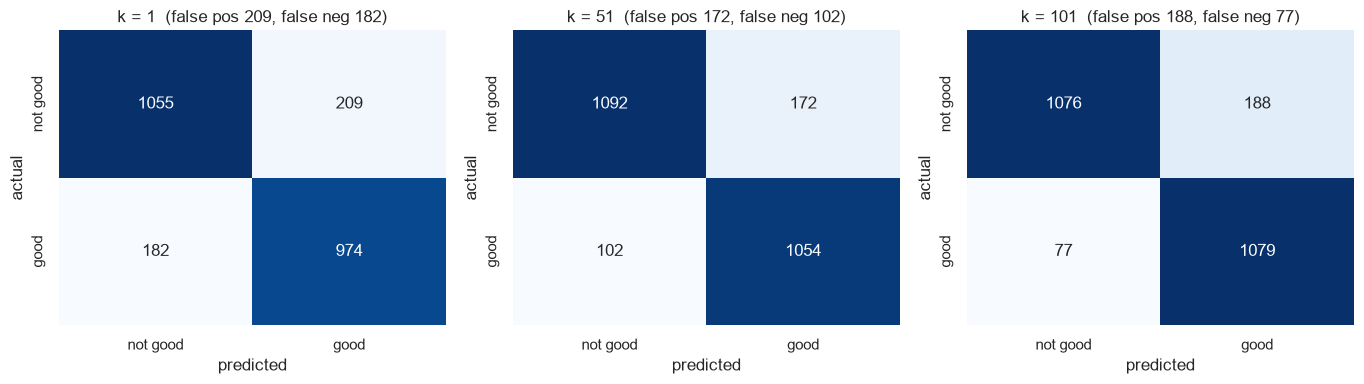

In [30]:
k_cv_best = int(k_num["CV F1 mean"].idxmax())
k_test_best = int(k_num["F1-score"].idxmax())
print("k with the best cross-validated F1 :", k_cv_best, "(CV F1 = %.4f)" % k_num.loc[k_cv_best, "CV F1 mean"])
print("k with the best test F1            :", k_test_best, "(test F1 = %.4f)" % k_num.loc[k_test_best, "F1-score"])
print("Test F1 at the k chosen by CV      : %.4f" % k_num.loc[k_cv_best, "F1-score"])

picks = sorted({1, k_cv_best, 101})
fig, axes = plt.subplots(1, len(picks), figsize=(4.6 * len(picks), 4))
for a, k in zip(np.atleast_1d(axes), picks):
    cm = confusion_matrix(y_test, lib_k[k].predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["not good", "good"], yticklabels=["not good", "good"])
    tn, fp, fn, tp = cm.ravel()
    a.set_title(f"k = {k}  (false pos {fp}, false neg {fn})"); a.set_xlabel("predicted"); a.set_ylabel("actual")
plt.tight_layout(); plt.show()

## 20. Other KNN settings: voting weights and distance type

k is not the only setting. We also compare plain voting (uniform) with distance weighted voting (closer neighbours count more), and the straight line (Euclidean) distance with the city block (Manhattan) distance, at several values of k.

In [31]:
rows = []
for metric in ["euclidean", "manhattan"]:
    for weights in ["uniform", "distance"]:
        for k in [1, 5, 15, 31, 51]:
            m = Pipeline([("scale", StandardScaler()),
                          ("clf", KNeighborsClassifier(n_neighbors=k, weights=weights, metric=metric))]).fit(X_train, y_train)
            pred = m.predict(X_test)
            rows.append({"setting": f"{metric:9s} | {weights:8s} | k = {k:2d}", "Train acc": m.score(X_train, y_train),
                         "Test acc": accuracy_score(y_test, pred), "F1-score": f1_score(y_test, pred)})
other = pd.DataFrame(rows).set_index("setting")
show(other)
print()
print("Best test F1 in this table:", other["F1-score"].idxmax(), "-> %.4f" % other["F1-score"].max())

euclidean | uniform  | k =  1:  Train acc = 1.0000,  Test acc = 0.8384,  F1-score = 0.8328
euclidean | uniform  | k =  5:  Train acc = 0.9842,  Test acc = 0.8496,  F1-score = 0.8447
euclidean | uniform  | k = 15:  Train acc = 0.9585,  Test acc = 0.8570,  F1-score = 0.8520
euclidean | uniform  | k = 31:  Train acc = 0.9311,  Test acc = 0.8727,  F1-score = 0.8703
euclidean | uniform  | k = 51:  Train acc = 0.9209,  Test acc = 0.8868,  F1-score = 0.8850
euclidean | distance | k =  1:  Train acc = 1.0000,  Test acc = 0.8384,  F1-score = 0.8328
euclidean | distance | k =  5:  Train acc = 1.0000,  Test acc = 0.8496,  F1-score = 0.8447
euclidean | distance | k = 15:  Train acc = 1.0000,  Test acc = 0.8566,  F1-score = 0.8519
euclidean | distance | k = 31:  Train acc = 1.0000,  Test acc = 0.8694,  F1-score = 0.8660
euclidean | distance | k = 51:  Train acc = 1.0000,  Test acc = 0.8860,  F1-score = 0.8840
manhattan | uniform  | k =  1:  Train acc = 1.0000,  Test acc = 0.8587,  F1-score = 0.8559

### What the different values of k tell us

All numbers below are from the tables above (test rows are countries the model never saw).

Small k overfits
* At k = 1 the training accuracy is exactly 1.000 (every row is its own nearest neighbour) but the test accuracy is only 0.838, a gap of 16.2 points. Test F1 is 0.833.
* The log loss at k = 1 is 5.82. A single neighbour always gives a probability of exactly 0 or 1, so every wrong answer is punished as hard as possible. This is by far the worst loss of all the models in this notebook.

Larger k smooths the model
* Test accuracy rises almost steadily from 0.838 (k = 1) to 0.891 (k = 75) and then stays flat (0.8905 at k = 101). Test F1 goes from 0.833 to 0.891 in the same way.
* The train-test gap shrinks from 16.2 points (k = 1) to 5.8 points (k = 31), 3.4 points (k = 51) and 1.9 points (k = 101). The training accuracy falls from 1.000 to 0.909, so the model stops memorising.
* ROC-AUC rises at every step from 0.839 (k = 1) to 0.962 (k = 101), and log loss falls from 5.82 to 0.26. Larger k gives better ranked and much more honest probabilities, because the vote now has many members and can give values between 0 and 1.

Precision and recall move differently
* Recall climbs from 0.843 (k = 1) to 0.933 (k = 101), while precision only moves between 0.823 and 0.860 (best at k = 51). So a large k makes KNN call more countries good: it misses fewer good countries but also makes a few more false alarms. For a health screening use, where missing a country in need is the worse mistake, this is a useful side effect. If false alarms are the worse mistake, a k around 51 balances the two better than k = 101.

Choosing k without touching the test rows
* The cross-validated F1 is best at k = 51 (0.8846). The values for k = 41, 75 and 101 (0.8823, 0.8819, 0.8800) are within one standard deviation (about 0.02 to 0.03) of it, so everything from about k = 31 upward is one flat region and the choice inside it is not important. What really matters is to avoid small k.
* The k chosen by cross-validation (51) gives a test F1 of 0.8850, and the best test F1 in the table is 0.8906 (k = 75 and 101). The difference is only 0.006, so choosing k by cross-validation cost almost nothing, and we did not need to look at the test rows.
* The grid search in Part A only offered k up to 25, so it picked k = 25 (accuracy 0.869). Allowing larger k lifts KNN to 0.887, which is above Decision Tree (0.875) and Naive Bayes (0.884) on accuracy. It is still below SVM (accuracy 0.907, F1 0.904). The lesson is that the range of the grid matters: a model can look weak just because the grid stopped too early.

Our own KNN against scikit-learn
* For every one of the 13 values of k our labels are the same as the scikit-learn labels on 100% of the test rows, so accuracy, precision, recall, F1 and ROC-AUC are identical (largest accuracy difference 0.0000).
* Only the log loss differs a little, and the difference is largest for small k (5.58 against 5.82 at k = 1) and almost disappears for large k (0.2595 against 0.2602 at k = 101). As explained in Part B, this comes from how the probabilities 0 and 1 are clipped before taking the log. With a large k there are fewer exact 0 or 1 probabilities, so the clipping matters less.
* Time: the scikit-learn prediction time grows with k, from 0.06 s (k = 1) to 0.21 s (k = 101). Our scratch version takes about 0.53 s for every k, because most of its time goes to the distance calculation, which does not depend on k.

Distance type and voting weights (section 20)
* The Manhattan distance beat the Euclidean distance at every k we tried. The difference is biggest for small k (test accuracy 0.859 against 0.838 at k = 1) and smaller for large k (0.892 against 0.887 at k = 51). With 13 columns, some of which may be noisy, the Manhattan distance is less affected by one column that differs a lot.
* Distance weighted voting did not help. It makes the training accuracy exactly 1.000 for every k (a training row is at distance 0 from itself and wins the vote), and its test accuracy is the same or slightly lower than plain voting (for example 0.869 against 0.873 at k = 31 with the Euclidean distance).
* The best setting in the table, Manhattan with plain voting and k = 51, gives test F1 0.891, the same as Euclidean with k = 75 or 101. KNN therefore gets close to, but does not beat, the F1 of the tuned SVM (0.904).

Caution: these results come from one split of the countries, and the cross-validation spread is 0.02 to 0.03, so differences of a few tenths of a point between neighbouring values of k should not be over-interpreted. The big trend (small k overfits, k of about 30 or more is stable) is clear and is the same in the training, cross-validation and test results.

# Part D: Final summary

## 21. How suitable is each algorithm for different classification tasks

SVM
* Good at: the best accuracy, F1 and loss here. It handles many linked numeric columns and overfits very little.
* Not good at: it is the slowest to train and gets slower quickly as rows increase. It needs scaling, is hard to explain, and its probabilities need extra work.
* Use it when: the data is small or medium, the columns are numbers, and accuracy matters more than speed or a simple explanation.

Decision Tree
* Good at: it is very easy to explain with if-then rules. It needs no scaling, it is fast, and it shows which columns matter.
* Not good at: it overfits when it is deep. Its probabilities are rough, so the loss is high. A small change in data can change the whole tree.
* Use it when: the decision must be explained to people, for example a health department, or the data has mixed kinds of columns.

KNN
* Good at: there is no training step, the idea is simple, and it works well for local patterns.
* Not good at: prediction is slow on big data. It is sensitive to scaling and to k (see Part C). It was hurt most by the repeated rows of the same country.
* Use it when: the data is small, the rows do not depend on each other, and we want a quick first try.

Naive Bayes
* Good at: it is extremely fast, it needs almost no tuning, it does not overfit, and its recall is high.
* Not good at: its main assumption is wrong for linked columns, so its probabilities are too sure and its loss is high.
* Use it when: there are very many columns (like text or spam filtering), the data is small, or we need a quick first try with high recall.

## 22. Ethical and social points

* Fairness between countries: the models learn from World Bank data, and poorer countries have more missing and filled-in values (see the limits below). A model that is less reliable for the poorest countries could wrongly label them, and such a label could influence where aid or attention goes. Results for these countries should be checked by people before any decision.
* Cost of mistakes: a false positive (a country called good that is not) can hide a country that needs help, and a false negative can send resources to a country that does not need them. Because the first mistake looks worse for a health use, recall and precision must be reported together, and the decision cut-off should be chosen on purpose.
* Explainability: public health decisions must be explained. The Decision Tree can be read by a non-expert, while SVM and KNN cannot, so a more accurate model is not always the right one to deploy.
* Data leakage and honest reporting: we removed columns that contain the answer and we split by country, so that the reported scores are not inflated. Reporting inflated scores would mislead the people who rely on them.
* Privacy: our data is country level and public, so no personal information is used. If the same models were used on patient records, consent, anonymisation and data protection rules would apply.
* Over-simplification: reducing life expectancy to good or not good with a 70-year line hides large differences inside each group. The result is a screening tool, not a final judgement on a country.

## 23. Overall conclusions

1. Classification: with only health and money related columns we can tell if life expectancy is above 70 years with about 87% to 91% accuracy for countries the model has never seen. SVM was the best on every main score. Naive Bayes was the fastest and best at recall, the Decision Tree is the easiest to explain, and KNN came last because the rows of one country are so alike.
2. From scratch and from the library: every algorithm we wrote by hand (KNN, Naive Bayes, Decision Tree and linear SVM) gave the same results as scikit-learn, apart from the tiny differences explained in Part B.
3. KNN and k: the value of k changes the result a lot. Very small k overfits (training accuracy close to 1 with a large drop on test countries), and very large k smooths the boundary too much. The detailed study in Part C shows the full table, plots and the k chosen by cross-validation.
4. Honest testing matters: we split by country and removed columns that give the answer away. With a random split, KNN and the Decision Tree would have looked much better than they really are.
5. Limits: our data has filled-in and capped values from the first assignment (for example the repeated 38.95 years), so the results for the poorest countries and the early years are less reliable. The 70-year cut-off is our own choice, and a different cut-off could change the order of the models a little.

Things we could try next
* Calibrate the SVM probabilities, or lower its decision cut-off to get a higher recall.
* Try gradient boosting and Random Forest classifiers and compare them with these four.
* Test by time, training on the earlier years and testing on the later years.

## 24. Reflection

* What we learned: writing the four classifiers ourselves showed that none of them is magic. KNN is a vote of the nearest rows, Naive Bayes is a product of bell curves, a Decision Tree is a list of yes or no questions, and a linear SVM is gradient descent on the hinge loss.
* What was difficult: avoiding leakage and the repeated rows of each country. Our first idea of a random split would have given scores that looked much better than the truth. We also had to understand why our log loss differed slightly from the library (probability clipping).
* What we would do differently: use a time based split, try more models, and study the model errors country by country for fairness.
* Skills we still need to build: probability calibration, handling of imbalanced classes and deeper work on model explanation.